# Intelligent Network Intrusion Detection & Attack Classification

**Dataset:** CICIDS2017 (CICFlowMeter flow features)
**Pipeline:** cleaning → feature engineering → feature selection → 6-model comparison → class-imbalance study → multiclass → cross-day (temporal) evaluation → Isolation Forest → SHAP

This notebook is organised to mirror the project synopsis (§5.1–§5.14). Every section has a short
markdown note explaining *what* it does and *why* before the code.

**How to run:** set `DATA_DIR` in the config cell to the folder containing the 8 CICIDS2017 CSVs, then
Run All. Nothing else is hardcoded.

> **Design notes / known CICIDS2017 pitfalls handled here**
> - The `Web Attack` labels are corrupted in the source CSVs (a byte that can't be decoded). We *normalise*
>   labels and group the three web-attack subtypes into one `Web Attack` family, matching the synopsis categories.
> - `Flow Bytes/s` and `Flow Packets/s` contain `inf` (division by zero-duration flows) and some `NaN` — handled.
> - `Fwd Header Length.1` is a duplicate of `Fwd Header Length` — dropped.
> - Several `Bulk`/flag columns are constant (zero variance) — dropped at runtime (computed, not hardcoded,
>   because which columns are constant depends on which files you load).
> - These CSVs have **no timestamp column**, so "temporal" evaluation is done as **train-on-earlier-days /
>   test-on-later-days** using the source filename — the standard realistic split for CICIDS2017.
> - Heavy models (RBF-SVM, KNN) scale poorly (~O(n²)); we cap the modelling set with a **stratified sample
>   that keeps *all* rows of rare attack classes**, so minority attacks are never lost to sampling.

## 0. Imports

In [1]:
import os, re, glob, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score, accuracy_score, roc_auc_score)

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

import joblib
# Note: we silence only sklearn's noisy Future/UserWarnings, NOT ConvergenceWarnings —
# if Logistic Regression fails to converge you WILL see it (and the log-transform in §7 fixes it).
from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter("ignore", category=FutureWarning)
warnings.simplefilter("ignore", category=UserWarning)
warnings.simplefilter("default", category=ConvergenceWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
print("Imports OK")

Imports OK


## 1. Configuration

The **only** thing you must edit is `DATA_DIR`. Point it at the folder that holds the 8 CICIDS2017 CSVs
(`Monday-WorkingHours...csv`, etc.).

`MAX_ROWS` caps the modelling set so RBF-SVM/KNN stay tractable. Rare attack classes are *never*
downsampled (see `smart_sample`). Raise it if you have time/RAM; lower it for a quick dry run.

> **Memory note:** loading all 8 files holds ~2.8M rows × 80 columns in memory — roughly **5–6 GB of RAM**
> during the load/clean step (before `MAX_ROWS` sampling kicks in). On an 8 GB laptop close other apps; on
> ≤4 GB, load a subset of the files instead.

In [ ]:
# >>>>>>>>>>>>>>>>>>>>  EDIT THIS  <<<<<<<<<<<<<<<<<<<<
DATA_DIR = "C:\ \Nikhil\\Manipal\\AI_Projects\\ML_Project\\MachineLearningCSV\\MachineLearningCVE"   # folder containing the 8 CICIDS2017 CSVs
# >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>

RANDOM_STATE  = 42
MAX_ROWS      = 100_000    # cap for the main modelling set (stratified; rare classes kept in full)
TEST_SIZE     = 0.20
RUN_TUNING    = False      # set True to run RandomizedSearchCV (slower) in §5.9
LOG_TRANSFORM = True       # signed-log the features before scaling — helps LogReg/SVM, harmless to trees
ARTIFACT_DIR  = "artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

np.random.seed(RANDOM_STATE)

# Chronological order of the capture days -> used for the temporal (cross-day) split in §5.11
DAY_ORDER = {"Monday":0, "Tuesday":1, "Wednesday":2, "Thursday":3, "Friday":4}

# Map raw CICIDS2017 labels -> coarse attack families (synopsis §5.7).
# Any label not listed falls back to itself.
FAMILY = {
    "BENIGN":"Benign",
    "DoS Hulk":"DoS", "DoS GoldenEye":"DoS", "DoS slowloris":"DoS",
    "DoS Slowhttptest":"DoS", "Heartbleed":"DoS",
    "DDoS":"DDoS",
    "PortScan":"PortScan",
    "FTP-Patator":"Brute Force", "SSH-Patator":"Brute Force",
    "Web Attack Brute Force":"Web Attack", "Web Attack XSS":"Web Attack",
    "Web Attack Sql Injection":"Web Attack",
    "Bot":"Bot",
    "Infiltration":"Infiltration",
}
print("DATA_DIR =", DATA_DIR)

DATA_DIR = C:\Nikhil\Manipal\AI_Projects\ML_Project\MachineLearningCSV\MachineLearningCVE


## 2. Dataset acquisition & loading  — synopsis §5.1

Loads every `*.csv` in `DATA_DIR`, strips the whitespace that CICIDS2017 puts in front of column names,
and tags each row with the capture **day** (from the filename) so we can do a cross-day split later.
Label text is normalised to repair the corrupted `Web Attack` labels.

In [3]:
def clean_label(s):
    # strip non-ASCII (the corrupted byte in the Web Attack labels) and collapse whitespace
    s = re.sub(r"[^\x00-\x7f]+", " ", str(s))
    return re.sub(r"\s+", " ", s).strip()

def day_from_name(fname):
    base = os.path.basename(fname)
    for day in DAY_ORDER:
        if base.lower().startswith(day.lower()):
            return day
    return "Unknown"

csv_files = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
assert csv_files, f"No CSV files found in {DATA_DIR!r} — fix DATA_DIR in the config cell."
print(f"Found {len(csv_files)} files:")
for f in csv_files: print("  ", os.path.basename(f))

frames = []
for f in csv_files:
    d = pd.read_csv(f, low_memory=False)
    d.columns = d.columns.str.strip()
    d["__day"] = day_from_name(f)
    frames.append(d)
df_raw = pd.concat(frames, ignore_index=True)
print("\nCombined raw shape:", df_raw.shape)

Found 8 files:
   Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
   Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
   Friday-WorkingHours-Morning.pcap_ISCX.csv
   Monday-WorkingHours.pcap_ISCX.csv
   Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
   Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
   Tuesday-WorkingHours.pcap_ISCX.csv
   Wednesday-workingHours.pcap_ISCX.csv

Combined raw shape: (2830743, 80)


In [4]:
# normalise labels and derive the coarse attack family
df_raw["Label"] = df_raw["Label"].apply(clean_label)
df_raw["attack_family"] = df_raw["Label"].map(FAMILY).fillna(df_raw["Label"])

print("Raw label counts:")
print(df_raw["Label"].value_counts())
print("\nAttack family counts:")
print(df_raw["attack_family"].value_counts())
print("\nRows per day:")
print(df_raw["__day"].value_counts())

Raw label counts:
Label
BENIGN                      2273097
DoS Hulk                     231073
PortScan                     158930
DDoS                         128027
DoS GoldenEye                 10293
FTP-Patator                    7938
SSH-Patator                    5897
DoS slowloris                  5796
DoS Slowhttptest               5499
Bot                            1966
Web Attack Brute Force         1507
Web Attack XSS                  652
Infiltration                     36
Web Attack Sql Injection         21
Heartbleed                       11
Name: count, dtype: int64

Attack family counts:
attack_family
Benign          2273097
DoS              252672
PortScan         158930
DDoS             128027
Brute Force       13835
Web Attack         2180
Bot                1966
Infiltration         36
Name: count, dtype: int64

Rows per day:
__day
Friday       703245
Wednesday    692703
Monday       529918
Thursday     458968
Tuesday      445909
Name: count, dtype: int64


## 3. Data preprocessing & cleaning  — synopsis §5.2

- Drop the duplicate `Fwd Header Length.1` column.
- Coerce all feature columns to numeric; replace `±inf` with `NaN`; drop rows with `NaN`.
- Drop exact duplicate rows.
- Drop zero-variance columns (computed on the data actually loaded, not hardcoded).
- Build the **multiclass** label (`attack_family`) and the **binary** target from it (0 = Benign, 1 = Attack).

*Leakage note:* all scaling/resampling later is fit on the **training split only**. Cleaning here only removes
broken rows/columns, which is safe to do before splitting.

In [5]:
df = df_raw.copy()

# 1) drop known duplicate column
if "Fwd Header Length.1" in df.columns:
    df = df.drop(columns=["Fwd Header Length.1"])

META = ["Label", "attack_family", "__day"]
feature_cols = [c for c in df.columns if c not in META]

# 2) numeric coercion + inf handling
df[feature_cols] = df[feature_cols].apply(pd.to_numeric, errors="coerce")
df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan)

before = len(df)
df = df.dropna(subset=feature_cols)
print(f"Dropped {before - len(df):,} rows with NaN/inf  ->  {len(df):,} rows")

# 3) exact duplicates
before = len(df)
df = df.drop_duplicates()
print(f"Dropped {before - len(df):,} duplicate rows      ->  {len(df):,} rows")

# 4) zero-variance columns (computed at runtime)
zero_var = [c for c in feature_cols if df[c].nunique() <= 1]
df = df.drop(columns=zero_var)
feature_cols = [c for c in feature_cols if c not in zero_var]
print(f"Dropped {len(zero_var)} zero-variance columns: {zero_var}")

# 5) targets
df["target"] = (df["attack_family"] != "Benign").astype(int)   # binary
print("\nBinary target balance:", df["target"].value_counts().to_dict())
print("Attack %: {:.2f}%".format(100 * df["target"].mean()))

Dropped 2,867 rows with NaN/inf  ->  2,827,876 rows
Dropped 264,769 duplicate rows      ->  2,563,107 rows
Dropped 8 zero-variance columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Binary target balance: {0: 2137366, 1: 425741}
Attack %: 16.61%


## 4. Exploratory data analysis  — synopsis §5.3

Class balance, a correlation overview, and a couple of feature distributions by class. Class imbalance is
the headline fact here: benign traffic dominates, so **accuracy is a misleading metric** — we lean on
recall, macro-F1 and the confusion matrix instead.

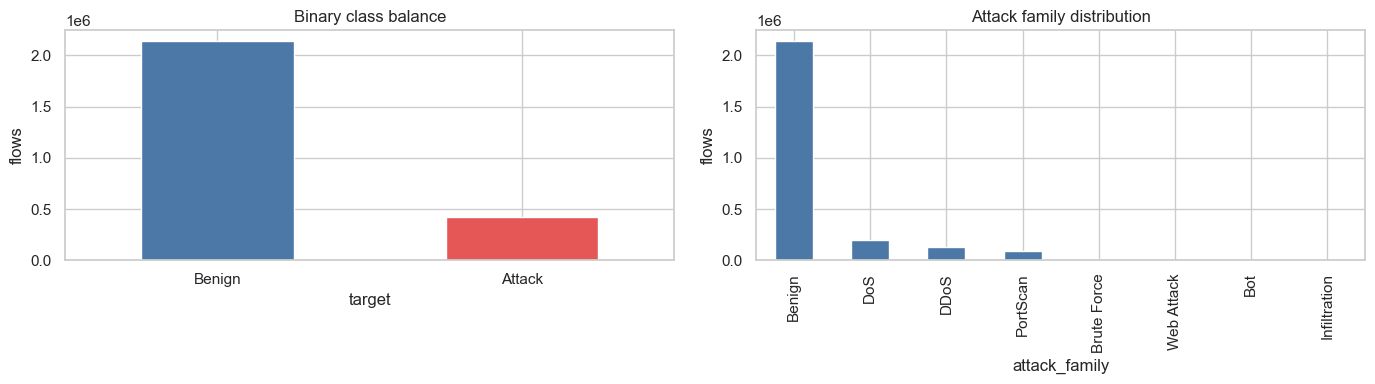

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df["target"].map({0:"Benign",1:"Attack"}).value_counts().plot.bar(ax=ax[0], color=["#4C78A8","#E45756"])
ax[0].set_title("Binary class balance"); ax[0].set_ylabel("flows"); ax[0].tick_params(axis='x', rotation=0)
df["attack_family"].value_counts().plot.bar(ax=ax[1], color="#4C78A8")
ax[1].set_title("Attack family distribution"); ax[1].set_ylabel("flows")
plt.tight_layout(); plt.show()

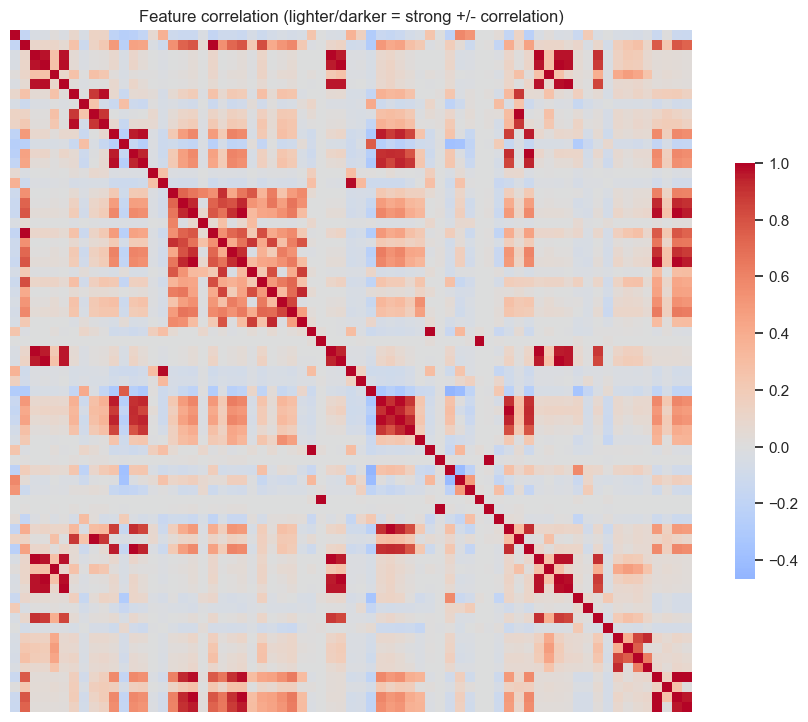

49 feature pairs with |corr| > 0.95 (redundant) — e.g.: [('Flow Duration', 'Fwd IAT Total', np.float64(1.0)), ('Total Fwd Packets', 'Total Backward Packets', np.float64(0.97)), ('Total Fwd Packets', 'Total Length of Bwd Packets', np.float64(0.97)), ('Total Fwd Packets', 'Fwd Header Length', np.float64(0.99)), ('Total Fwd Packets', 'Subflow Fwd Packets', np.float64(1.0))]


In [7]:
# correlation heatmap on a feature subset (full 60+ is unreadable); sample rows for speed
corr_sample = df[feature_cols].sample(min(20000, len(df)), random_state=RANDOM_STATE).corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr_sample, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink":0.6},
            xticklabels=False, yticklabels=False)
plt.title("Feature correlation (lighter/darker = strong +/- correlation)")
plt.show()

# how many highly-correlated pairs exist (motivates feature selection in §5.5)
cc = corr_sample.abs()
upper = cc.where(np.triu(np.ones(cc.shape), k=1).astype(bool))
high = [(a, b, round(upper.loc[a, b], 2)) for a in upper.index for b in upper.columns
        if pd.notnull(upper.loc[a, b]) and upper.loc[a, b] > 0.95]
print(f"{len(high)} feature pairs with |corr| > 0.95 (redundant) — e.g.:", high[:5])

## 5. Feature engineering  — synopsis §5.4

Derive ratio/rate features that capture *flow behaviour* rather than raw counts. All divisions are
zero-safe (`÷0 → NaN → 0`) so we never reintroduce `inf`. We compare model performance **with vs without**
these features in §8.

In [8]:
def safe_div(a, b):
    return a / b.replace(0, np.nan)

def add_engineered(frame):
    e = pd.DataFrame(index=frame.index)
    tot_pkts  = frame["Total Fwd Packets"] + frame["Total Backward Packets"]
    tot_bytes = frame["Total Length of Fwd Packets"] + frame["Total Length of Bwd Packets"]
    e["fwd_bwd_pkt_ratio"]  = safe_div(frame["Total Fwd Packets"], frame["Total Backward Packets"])
    e["fwd_bwd_byte_ratio"] = safe_div(frame["Total Length of Fwd Packets"], frame["Total Length of Bwd Packets"])
    e["avg_pkt_size"]       = safe_div(tot_bytes, tot_pkts)
    e["bytes_per_sec_flow"] = safe_div(tot_bytes, frame["Flow Duration"])
    e["pkts_per_sec_flow"]  = safe_div(tot_pkts,  frame["Flow Duration"])
    if "SYN Flag Count" in frame and "ACK Flag Count" in frame:
        e["syn_ack_ratio"]  = safe_div(frame["SYN Flag Count"], frame["ACK Flag Count"])
    return e.replace([np.inf, -np.inf], np.nan).fillna(0)

ENG = add_engineered(df)
engineered_cols = ENG.columns.tolist()
df = pd.concat([df, ENG], axis=1)
print("Added engineered features:", engineered_cols)
print("New inf introduced:", int(np.isinf(df[engineered_cols]).sum().sum()))

ALL_FEATURES = feature_cols + engineered_cols
print(f"\nTotal features: {len(ALL_FEATURES)}  ({len(feature_cols)} original + {len(engineered_cols)} engineered)")

Added engineered features: ['fwd_bwd_pkt_ratio', 'fwd_bwd_byte_ratio', 'avg_pkt_size', 'bytes_per_sec_flow', 'pkts_per_sec_flow', 'syn_ack_ratio']
New inf introduced: 0

Total features: 75  (69 original + 6 engineered)


### Stratified sampling (keeps all rare-attack rows) + train/test split

`smart_sample` caps the dataset to `MAX_ROWS` but keeps **every** row of any class that is already small,
so rare attacks (Bot, Infiltration, …) are not wiped out by sampling — the bug in the original notebook,
where `nrows=50000` silently kept only the first rows of each file and reduced Bot to 2 samples.

In [9]:
def smart_sample(frame, label_col, max_rows, rs=RANDOM_STATE):
    if len(frame) <= max_rows:
        return frame.copy()
    frac = max_rows / len(frame)
    keep = []
    rng = np.random.RandomState(rs)
    for c, grp in frame.groupby(label_col):
        if len(grp) * frac < 1000:        # small class -> keep all of it
            keep.append(grp)
        else:
            keep.append(grp.sample(int(len(grp) * frac), random_state=rs))
    return pd.concat(keep).sample(frac=1, random_state=rs)   # shuffle

model_df = smart_sample(df, "attack_family", MAX_ROWS)
print(f"Modelling set: {len(model_df):,} rows (from {len(df):,})")
print("Family balance in modelling set:")
print(model_df["attack_family"].value_counts())
print(f"\nAttack % — full data: {100*df['target'].mean():.2f}%  |  modelling sample: "
      f"{100*(model_df['attack_family']!='Benign').mean():.2f}%")
print("NOTE: keeping all rare-attack rows raises the attack share in the sample above the real-world rate.")
print("      Precision and false-positive rates below are therefore optimistic vs. live traffic.")

Modelling set: 112,757 rows (from 2,563,107)
Family balance in modelling set:
attack_family
Benign          83389
Brute Force      9150
DoS              7559
DDoS             4994
PortScan         3538
Web Attack       2143
Bot              1948
Infiltration       36
Name: count, dtype: int64

Attack % — full data: 16.61%  |  modelling sample: 26.05%
NOTE: keeping all rare-attack rows raises the attack share in the sample above the real-world rate.
      Precision and false-positive rates below are therefore optimistic vs. live traffic.


In [10]:
def _signed_log(X):
    # signed log1p: compresses the huge dynamic range of flow features (durations, byte counts)
    # while tolerating the negative sentinels CICIDS2017 uses (e.g. Init_Win_bytes = -1).
    return np.sign(X) * np.log1p(np.abs(X))

def make_preprocessor():
    steps = []
    if LOG_TRANSFORM:
        steps.append(("signed_log", FunctionTransformer(_signed_log, feature_names_out="one-to-one")))
    steps.append(("scale", StandardScaler()))
    return Pipeline(steps)

def split_and_scale(frame, feats, target_col, stratify_col=None):
    X = frame[feats]
    y = frame[target_col]
    strat = frame[stratify_col] if stratify_col else y
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=strat)
    prep = make_preprocessor().fit(Xtr)         # fit on TRAIN only (no leakage)
    return (prep.transform(Xtr), prep.transform(Xte), ytr.values, yte.values, prep)

X_train, X_test, y_train, y_test, scaler = split_and_scale(
    model_df, ALL_FEATURES, "target", stratify_col="target")
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train attack %:", round(100*y_train.mean(),2), " Test attack %:", round(100*y_test.mean(),2))
print("Preprocessing:", "signed-log + StandardScaler" if LOG_TRANSFORM else "StandardScaler only")

Train: (90205, 75)  Test: (22552, 75)
Train attack %: 26.05  Test attack %: 26.05
Preprocessing: signed-log + StandardScaler


## 6. Feature selection  — synopsis §5.5

Three complementary views of which features matter: **mutual information**, **tree-based importance**, and
**correlation pruning**. We report the rankings and keep a `top-k` list you can swap into the models to test
the accuracy-vs-dimensionality trade-off (synopsis asks for top-50/25/10 comparisons).

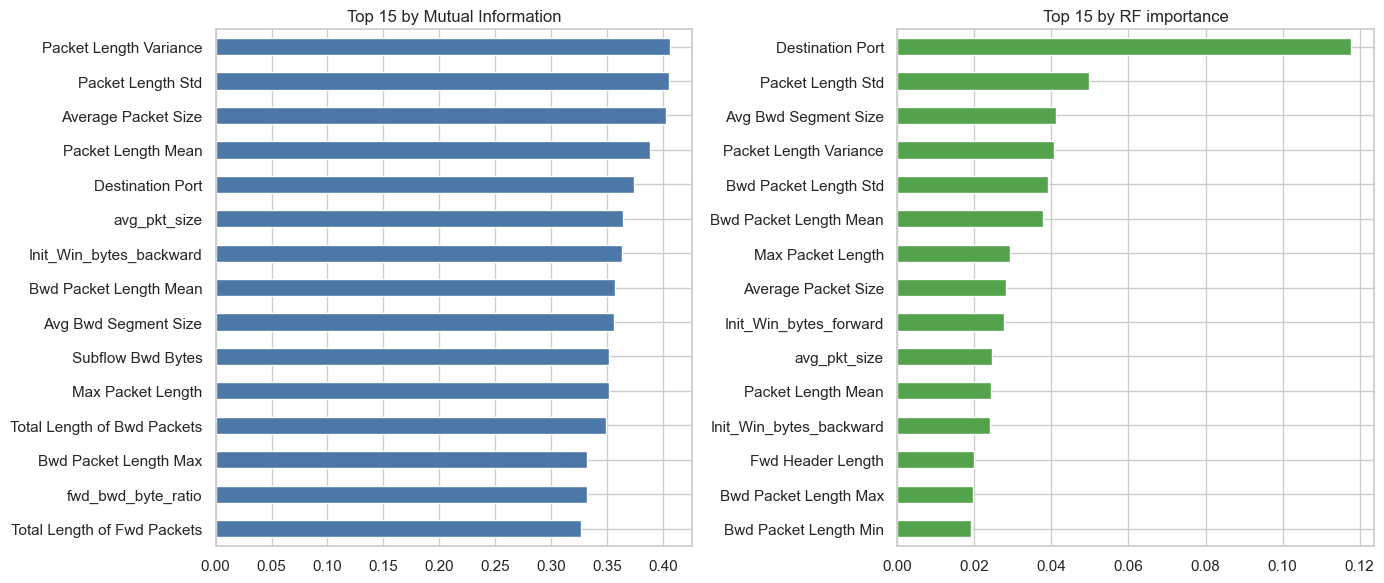

Selected top-25 features (by RF importance):
['Destination Port', 'Packet Length Std', 'Avg Bwd Segment Size', 'Packet Length Variance', 'Bwd Packet Length Std', 'Bwd Packet Length Mean', 'Max Packet Length', 'Average Packet Size', 'Init_Win_bytes_forward', 'avg_pkt_size', 'Packet Length Mean', 'Init_Win_bytes_backward', 'Fwd Header Length', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Fwd IAT Std', 'Fwd Packet Length Max', 'Fwd IAT Min', 'PSH Flag Count', 'Total Length of Fwd Packets', 'Bwd Header Length', 'Flow IAT Std', 'Subflow Fwd Bytes', 'Total Backward Packets', 'act_data_pkt_fwd']


In [11]:
# Mutual information
mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
mi_rank = pd.Series(mi, index=ALL_FEATURES).sort_values(ascending=False)

# Tree-based importance
rf_imp = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
rf_imp.fit(X_train, y_train)
imp_rank = pd.Series(rf_imp.feature_importances_, index=ALL_FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
mi_rank.head(15).iloc[::-1].plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Top 15 by Mutual Information")
imp_rank.head(15).iloc[::-1].plot.barh(ax=ax[1], color="#54A24B"); ax[1].set_title("Top 15 by RF importance")
plt.tight_layout(); plt.show()

TOP_K = 25
top_features = imp_rank.head(TOP_K).index.tolist()
print(f"Selected top-{TOP_K} features (by RF importance):")
print(top_features)

In [12]:
# OPTIONAL: compare full feature set vs top-k on a quick RandomForest
for name, feats in [("all features", ALL_FEATURES), (f"top-{TOP_K}", top_features)]:
    Xtr, Xte, ytr, yte, _ = split_and_scale(model_df, feats, "target", stratify_col="target")
    m = RandomForestClassifier(n_estimators=100, n_jobs=-1, class_weight="balanced",
                               random_state=RANDOM_STATE).fit(Xtr, ytr)
    print(f"{name:12s}  macro-F1 = {f1_score(yte, m.predict(Xte), average='macro'):.4f}  "
          f"({len(feats)} features)")

all features  macro-F1 = 0.9971  (75 features)
top-25        macro-F1 = 0.9977  (25 features)


## 7. Binary classification — 6-model comparison  — synopsis §5.6 & §5.8

All six classical models trained with a **single unified interface** on the *same* train/test split, so the
comparison is fair. We report accuracy, precision, recall, macro-F1, ROC-AUC, and fit/inference time.
Because missing an attack is the costly error, **recall and macro-F1 matter more than accuracy.**

In [13]:
def build_models(class_weight="balanced"):
    return {
        "LogReg":       LogisticRegression(max_iter=2000, class_weight=class_weight,
                                           random_state=RANDOM_STATE, n_jobs=-1),
        "KNN":          KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        "DecisionTree": DecisionTreeClassifier(class_weight=class_weight, random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                               class_weight=class_weight, random_state=RANDOM_STATE),
        "SVM":          SVC(kernel="rbf", class_weight=class_weight, random_state=RANDOM_STATE),
        "XGBoost":      XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, n_jobs=-1,
                                      eval_metric="logloss", random_state=RANDOM_STATE),
    }

def evaluate(name, model, Xtr, ytr, Xte, yte, average="binary"):
    t = time.time(); model.fit(Xtr, ytr);     fit_s = time.time() - t
    t = time.time(); y_pred = model.predict(Xte); inf_s = time.time() - t
    # ROC-AUC (binary only, needs a score)
    auc = np.nan
    if average == "binary":
        try:
            score = model.predict_proba(Xte)[:, 1] if hasattr(model, "predict_proba") \
                    else model.decision_function(Xte)
            auc = roc_auc_score(yte, score)
        except Exception:
            pass
    return {
        "model": name,
        "accuracy":  accuracy_score(yte, y_pred),
        "precision": precision_score(yte, y_pred, average=average, zero_division=0),
        "recall":    recall_score(yte, y_pred, average=average, zero_division=0),
        "macro_f1":  f1_score(yte, y_pred, average="macro"),
        "roc_auc":   auc,
        "fit_s":     round(fit_s, 2),
        "infer_s":   round(inf_s, 3),
    }

results = []
for name, model in build_models(class_weight="balanced").items():
    r = evaluate(name, model, X_train, y_train, X_test, y_test)
    results.append(r)
    print(f"  done: {name:13s} macro-F1={r['macro_f1']:.4f}  recall={r['recall']:.4f}  fit={r['fit_s']}s")

binary_results = pd.DataFrame(results).set_index("model").sort_values("macro_f1", ascending=False)
print()
binary_results.round(4)

  done: LogReg        macro-F1=0.9331  recall=0.9498  fit=9.32s
  done: KNN           macro-F1=0.9945  recall=0.9947  fit=0.06s
  done: DecisionTree  macro-F1=0.9951  recall=0.9930  fit=6.25s
  done: RandomForest  macro-F1=0.9971  recall=0.9940  fit=8.19s
  done: SVM           macro-F1=0.9840  recall=0.9808  fit=100.7s
  done: XGBoost       macro-F1=0.9986  recall=0.9990  fit=2.8s



,accuracy,precision,recall,macro_f1,roc_auc,fit_s,infer_s
model,,,,,,,
XGBoost,0.9989,0.9968,0.9990,0.9986,1.0000,2.80,0.015
RandomForest,0.9977,0.9973,0.9940,0.9971,0.9997,8.19,0.147
DecisionTree,0.9962,0.9925,0.9930,0.9951,0.9952,6.25,0.015
KNN,0.9958,0.9892,0.9947,0.9945,0.9983,0.06,12.402
SVM,0.9876,0.9720,0.9808,0.9840,0.9988,100.70,29.361
LogReg,0.9467,0.8603,0.9498,0.9331,0.9876,9.32,0.005


Best binary model: XGBoost

              precision    recall  f1-score   support

      Benign     0.9996    0.9989    0.9993     16678
      Attack     0.9968    0.9990    0.9979      5874

    accuracy                         0.9989     22552
   macro avg     0.9982    0.9989    0.9986     22552
weighted avg     0.9989    0.9989    0.9989     22552



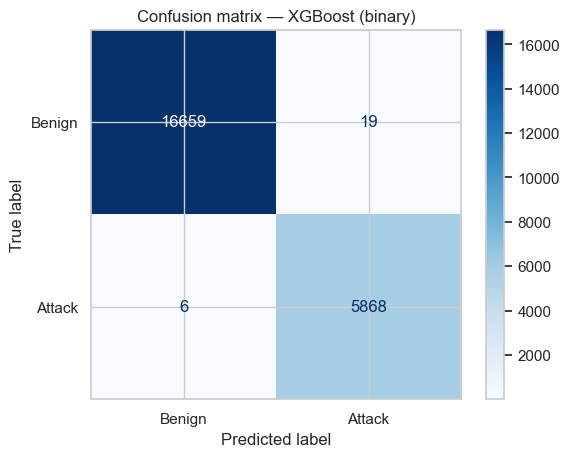

In [14]:
# Confusion matrix + full report for the best binary model
best_name = binary_results.index[0]
best_model = build_models("balanced")[best_name].fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print(f"Best binary model: {best_name}\n")
print(classification_report(y_test, y_pred, target_names=["Benign","Attack"], digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Benign","Attack"]).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix — {best_name} (binary)"); plt.show()

## 8. Leakage check: does the model just memorise `Destination Port`?

`Destination Port` is consistently a top feature on CICIDS2017, and several attacks sit on fixed ports (SSH 22,
FTP 21, …). A model could shortcut on the port number instead of learning traffic *behaviour*. We re-train the
best model with that column removed and compare — if performance barely moves, the model is learning behaviour;
if it collapses, it was leaning on the port.

In [15]:
if "Destination Port" in ALL_FEATURES:
    feats_noport = [f for f in ALL_FEATURES if f != "Destination Port"]
    Xtr_p, Xte_p, ytr_p, yte_p, _ = split_and_scale(model_df, feats_noport, "target", stratify_col="target")
    m_noport = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, n_jobs=-1,
                             eval_metric="logloss", random_state=RANDOM_STATE).fit(Xtr_p, ytr_p)
    yp_p = m_noport.predict(Xte_p)
    with_port = f1_score(y_test, best_model.predict(X_test), average="macro")
    no_port   = f1_score(yte_p, yp_p, average="macro")
    print(f"XGBoost macro-F1 WITH Destination Port : {with_port:.4f}")
    print(f"XGBoost macro-F1 WITHOUT it            : {no_port:.4f}")
    print(f"Drop: {with_port - no_port:+.4f}")
    print("\nSmall drop  -> model relies on behaviour, port is a minor help (good).")
    print("Large drop  -> model was leaning on the port number (leakage risk; report it).")
else:
    print("Destination Port not in feature set — nothing to test.")

XGBoost macro-F1 WITH Destination Port : 0.9986
XGBoost macro-F1 WITHOUT it            : 0.9975
Drop: +0.0011

Small drop  -> model relies on behaviour, port is a minor help (good).
Large drop  -> model was leaning on the port number (leakage risk; report it).


## 9. Class-imbalance study  — synopsis §5.10

Compare four strategies on a representative model (RandomForest): the raw imbalanced data, class-weighting,
SMOTE oversampling, and random undersampling. SMOTE's `k_neighbors` is clamped so it never exceeds the
smallest class size.

In [16]:
def resample(strategy, Xtr, ytr):
    if strategy == "raw":
        return Xtr, ytr
    if strategy == "smote":
        k = max(1, min(5, pd.Series(ytr).value_counts().min() - 1))
        return SMOTE(random_state=RANDOM_STATE, k_neighbors=k).fit_resample(Xtr, ytr)
    if strategy == "undersample":
        return RandomUnderSampler(random_state=RANDOM_STATE).fit_resample(Xtr, ytr)

rows = []
for strat in ["raw", "class_weight", "smote", "undersample"]:
    if strat == "class_weight":
        Xa, ya = X_train, y_train
        m = RandomForestClassifier(n_estimators=100, n_jobs=-1, class_weight="balanced",
                                   random_state=RANDOM_STATE)
    else:
        Xa, ya = resample(strat, X_train, y_train)
        m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
    m.fit(Xa, ya); yp = m.predict(X_test)
    rows.append({"strategy": strat,
                 "precision": precision_score(y_test, yp, zero_division=0),
                 "recall":    recall_score(y_test, yp, zero_division=0),
                 "macro_f1":  f1_score(y_test, yp, average="macro"),
                 "train_rows": len(ya)})
pd.DataFrame(rows).set_index("strategy").round(4)

,precision,recall,macro_f1,train_rows
strategy,,,,
raw,0.9976,0.9940,0.9972,90205
class_weight,0.9973,0.9940,0.9971,90205
smote,0.9961,0.9952,0.9971,133422
undersample,0.9952,0.9954,0.9968,46988


## 10. Multiclass attack classification  — synopsis §5.7

Now predict the specific attack family. (With a single file loaded you'll only see Benign + that file's
attack type; load all 8 files to get the full set of families.) The confusion matrix shows which attacks get
confused with which.

> **Caveat for the report:** `Infiltration` has only ~36 flows in the entire dataset (≈7 in the test split),
> so its per-class recall rests on a handful of samples and swings wildly — it is the main drag on the
> **macro**-F1 (which weights every class equally). Weighted-F1 stays ~0.999 because the class is tiny. Report
> both, and don't over-interpret the Infiltration number.

Classes: ['Benign', 'Bot', 'Brute Force', 'DDoS', 'DoS', 'Infiltration', 'PortScan', 'Web Attack']

Multiclass macro-F1: 0.9758
              precision    recall  f1-score   support

      Benign     0.9995    0.9989    0.9992     16678
         Bot     0.9748    0.9949    0.9847       389
 Brute Force     1.0000    1.0000    1.0000      1830
        DDoS     0.9990    1.0000    0.9995       999
         DoS     0.9974    0.9987    0.9980      1512
Infiltration     1.0000    0.7143    0.8333         7
    PortScan     0.9916    0.9958    0.9937       708
  Web Attack     1.0000    0.9953    0.9977       429

    accuracy                         0.9987     22552
   macro avg     0.9953    0.9622    0.9758     22552
weighted avg     0.9987    0.9987    0.9987     22552



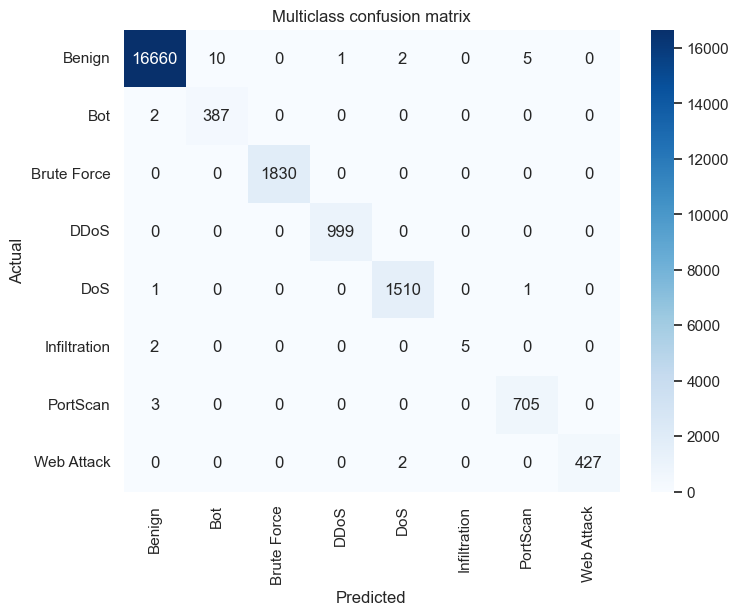

In [17]:
le = LabelEncoder()
y_multi = le.fit_transform(model_df["attack_family"])
classes = list(le.classes_)
print("Classes:", classes)

if len(classes) < 3:
    print("\n[Only", len(classes), "classes present — load all 8 CSVs for a real multiclass problem.]")

Xm = model_df[ALL_FEATURES]
Xtr_m, Xte_m, ytr_m, yte_m = train_test_split(
    Xm, y_multi, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_multi)
sc_m = StandardScaler().fit(Xtr_m)
Xtr_m, Xte_m = sc_m.transform(Xtr_m), sc_m.transform(Xte_m)

mc = XGBClassifier(n_estimators=300, max_depth=7, learning_rate=0.1, n_jobs=-1,
                   eval_metric="mlogloss", random_state=RANDOM_STATE)
mc.fit(Xtr_m, ytr_m)
yp_m = mc.predict(Xte_m)
print("\nMulticlass macro-F1:", round(f1_score(yte_m, yp_m, average="macro"), 4))
print(classification_report(yte_m, yp_m, target_names=classes, digits=4))

cm = confusion_matrix(yte_m, yp_m)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Multiclass confusion matrix"); plt.show()

## 11. Hyperparameter optimisation  — synopsis §5.9

`RandomizedSearchCV` on the two strongest models (RandomForest, XGBoost), optimising **macro-F1** (the metric
that respects minority classes). Off by default (`RUN_TUNING=False`) because it is the slowest cell — flip the
flag in the config to run it.

In [18]:
if RUN_TUNING:
    rf_space = {"n_estimators":[100,200,400], "max_depth":[None,10,20,30],
                "min_samples_split":[2,5,10], "max_features":["sqrt","log2"]}
    rf_search = RandomizedSearchCV(
        RandomForestClassifier(n_jobs=-1, class_weight="balanced", random_state=RANDOM_STATE),
        rf_space, n_iter=8, scoring="f1_macro", cv=3, random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
    rf_search.fit(X_train, y_train)
    print("Best RF params:", rf_search.best_params_)
    print("Best CV macro-F1:", round(rf_search.best_score_, 4))

    xgb_space = {"n_estimators":[200,400], "max_depth":[4,6,8],
                 "learning_rate":[0.05,0.1,0.2], "subsample":[0.8,1.0]}
    xgb_search = RandomizedSearchCV(
        XGBClassifier(n_jobs=-1, eval_metric="logloss", random_state=RANDOM_STATE),
        xgb_space, n_iter=8, scoring="f1_macro", cv=3, random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
    xgb_search.fit(X_train, y_train)
    print("Best XGB params:", xgb_search.best_params_)
    print("Best CV macro-F1:", round(xgb_search.best_score_, 4))
else:
    print("RUN_TUNING is False — set it True in the config cell to run hyperparameter search.")

RUN_TUNING is False — set it True in the config cell to run hyperparameter search.


## 12. Temporal / cross-day generalisation  — synopsis §5.11

The honest test: can a model trained on **earlier** days detect attacks on **later** days?

**This split is only meaningful if the training days actually contain a variety of attacks.** The naive
"first half of days vs second half" split fails here because Monday has *zero* attacks and Tuesday has *only*
brute-force — so a model trained on Mon+Tue has never seen DoS, DDoS, PortScan, etc., and scores ~0% recall on
later days. That result measures **"can't detect unseen attack types,"** not temporal drift.

So we train on **Monday–Wednesday** (which between them cover brute-force, DoS, DDoS *and* PortScan) and test on
**Thursday–Friday** (web attacks, infiltration, bot, more DDoS/PortScan). We print the attack-family coverage of
each side so you can see exactly what the model was and wasn't trained on — and interpret the number honestly.

*Needs ≥2 distinct days.* With one file it falls back to an ordered within-file split and says so.

In [19]:
days_present = sorted([d for d in DAY_ORDER if d in set(df["__day"])], key=lambda d: DAY_ORDER[d])
print("Days present:", days_present)

def family_coverage(frame):
    fams = frame.loc[frame["attack_family"] != "Benign", "attack_family"].value_counts()
    return fams.to_dict()

if len(days_present) >= 3:
    # hold out the last 2 capture days; train on all earlier days (Mon-Wed / Thu-Fri on the full set)
    test_days  = days_present[-2:]
    train_days = days_present[:-2]
elif len(days_present) == 2:
    train_days, test_days = days_present[:1], days_present[1:]
else:
    train_days = test_days = None

if train_days:
    print(f"\nTemporal split -> TRAIN on {train_days}  |  TEST on {test_days}")
    tr = df[df["__day"].isin(train_days)]
    te = df[df["__day"].isin(test_days)]
    print("  Train attack families:", family_coverage(tr))
    print("  Test  attack families:", family_coverage(te))
    unseen = set(family_coverage(te)) - set(family_coverage(tr))
    if unseen:
        print(f"  NOTE: these attack families appear ONLY in the test set (never trained on): {sorted(unseen)}")

    tr = smart_sample(tr, "attack_family", MAX_ROWS)
    prep_t = make_preprocessor().fit(tr[ALL_FEATURES])
    m = RandomForestClassifier(n_estimators=100, n_jobs=-1, class_weight="balanced",
                               random_state=RANDOM_STATE).fit(prep_t.transform(tr[ALL_FEATURES]), tr["target"])
    yp_t = m.predict(prep_t.transform(te[ALL_FEATURES]))
    print("\nCROSS-DAY (temporal) performance:")
    print(classification_report(te["target"], yp_t, target_names=["Benign","Attack"], digits=4))
    print("Compare attack-recall here with the random-split recall in §7 — the gap is the")
    print("real cost of generalising to a later day, AFTER controlling for attack-type coverage.")
else:
    print("[Only one day present — load all 8 files for a true cross-day test.]")
    ordered = df.sort_index()
    n = int(len(ordered) * (1 - TEST_SIZE))
    tr, te = ordered.iloc[:n], ordered.iloc[n:]
    prep_t = make_preprocessor().fit(tr[ALL_FEATURES])
    m = RandomForestClassifier(n_estimators=100, n_jobs=-1, class_weight="balanced",
                               random_state=RANDOM_STATE).fit(prep_t.transform(tr[ALL_FEATURES]), tr["target"])
    yp_t = m.predict(prep_t.transform(te[ALL_FEATURES]))
    print(classification_report(te["target"], yp_t, target_names=["Benign","Attack"], digits=4))

Days present: ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']

Temporal split -> TRAIN on ['Monday', 'Tuesday', 'Wednesday']  |  TEST on ['Thursday', 'Friday']
  Train attack families: {'DoS': 193756, 'Brute Force': 9150}
  Test  attack families: {'DDoS': 128014, 'PortScan': 90694, 'Web Attack': 2143, 'Bot': 1948, 'Infiltration': 36}
  NOTE: these attack families appear ONLY in the test set (never trained on): ['Bot', 'DDoS', 'Infiltration', 'PortScan', 'Web Attack']

CROSS-DAY (temporal) performance:
              precision    recall  f1-score   support

      Benign     0.8504    0.9996    0.9190    805504
      Attack     0.9964    0.3645    0.5338    222835

    accuracy                         0.8620   1028339
   macro avg     0.9234    0.6821    0.7264   1028339
weighted avg     0.8821    0.8620    0.8355   1028339

Compare attack-recall here with the random-split recall in §7 — the gap is the
real cost of generalising to a later day, AFTER controlling for attack-type co

## 13. Anomaly detection with Isolation Forest  — synopsis §5.12

Trained on **benign traffic only**, Isolation Forest flags flows that deviate from "normal". This catches
*unknown* attacks a supervised model never saw — but note it tends to catch **volumetric** anomalies
(DDoS, PortScan) far better than stealthy low-volume ones (web attacks that look like normal HTTP). The
recall it reports is a realistic look at that limitation.

In [20]:
benign_train = X_train[y_train == 0]
iso = IsolationForest(contamination=0.02, random_state=RANDOM_STATE, n_jobs=-1).fit(benign_train)

iso_pred = (iso.predict(X_test) == -1).astype(int)   # -1 = anomaly -> treat as attack
print("Isolation Forest (unsupervised, trained on benign only):")
print(classification_report(y_test, iso_pred, target_names=["Benign","Attack"], digits=4))
print("Attacks caught (recall):", round(recall_score(y_test, iso_pred), 4))
print("Benign wrongly flagged (false-positive rate):", round(iso_pred[y_test == 0].mean(), 4))

Isolation Forest (unsupervised, trained on benign only):
              precision    recall  f1-score   support

      Benign     0.7378    0.9809    0.8421     16678
      Attack     0.1561    0.0100    0.0189      5874

    accuracy                         0.7280     22552
   macro avg     0.4469    0.4955    0.4305     22552
weighted avg     0.5863    0.7280    0.6277     22552

Attacks caught (recall): 0.01
Benign wrongly flagged (false-positive rate): 0.0191


## 14. Explainability with SHAP  — synopsis §5.13

Why did the model flag a flow? SHAP attributes each prediction to its features. We use the tree explainer on
RandomForest. The summary plot shows which features drive attack predictions globally.

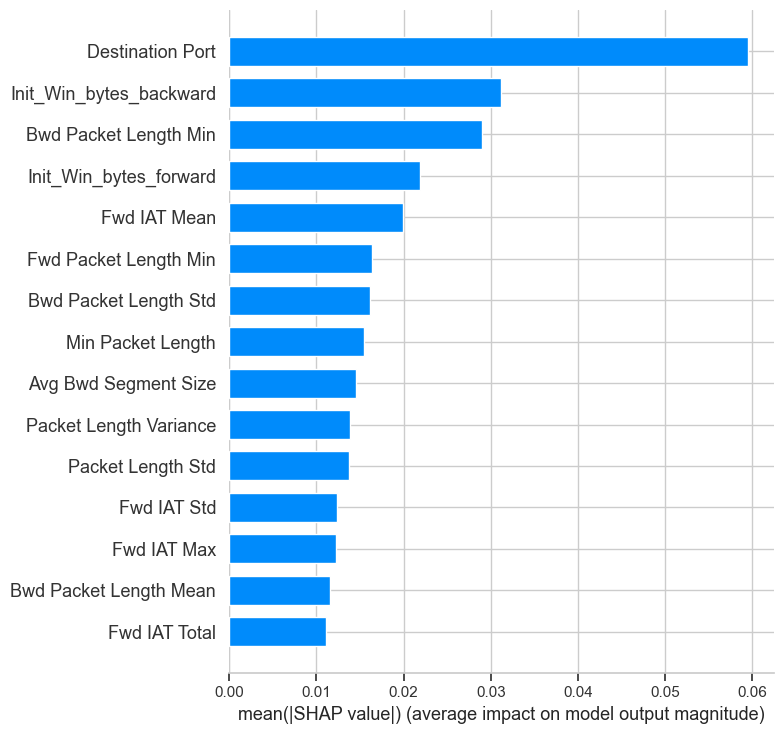

In [21]:
import shap
expl_model = RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                    class_weight="balanced", random_state=RANDOM_STATE).fit(X_train, y_train)
explainer = shap.TreeExplainer(expl_model)

sample = X_test[:500]
sv = explainer.shap_values(sample)
# newer SHAP returns array (n, features, classes); pick the 'attack' class
if isinstance(sv, list):
    sv_attack = sv[1]
elif np.ndim(sv) == 3:
    sv_attack = sv[:, :, 1]
else:
    sv_attack = sv
shap.summary_plot(sv_attack, pd.DataFrame(sample, columns=ALL_FEATURES),
                  plot_type="bar", max_display=15, show=True)

## 15. Consolidated results & saved artifacts  — synopsis §5.14

The final comparison table and the saved model/scaler so the project is reproducible. This is the table that
goes into your report.

In [22]:
print("="*70)
print("FINAL BINARY MODEL COMPARISON")
print("="*70)
display(binary_results.round(4))

binary_results.to_csv(os.path.join(ARTIFACT_DIR, "binary_model_comparison.csv"))
joblib.dump(best_model, os.path.join(ARTIFACT_DIR, "best_binary_model.pkl"))
joblib.dump(scaler,     os.path.join(ARTIFACT_DIR, "scaler.pkl"))
joblib.dump(mc,         os.path.join(ARTIFACT_DIR, "multiclass_model.pkl"))
joblib.dump(le,         os.path.join(ARTIFACT_DIR, "label_encoder.pkl"))
with open(os.path.join(ARTIFACT_DIR, "feature_list.json"), "w") as fh:
    json.dump({"all_features": ALL_FEATURES, "top_features": top_features}, fh, indent=2)
print("\nSaved to", ARTIFACT_DIR, ":", os.listdir(ARTIFACT_DIR))

FINAL BINARY MODEL COMPARISON


,accuracy,precision,recall,macro_f1,roc_auc,fit_s,infer_s
model,,,,,,,
XGBoost,0.9989,0.9968,0.9990,0.9986,1.0000,2.80,0.015
RandomForest,0.9977,0.9973,0.9940,0.9971,0.9997,8.19,0.147
DecisionTree,0.9962,0.9925,0.9930,0.9951,0.9952,6.25,0.015
KNN,0.9958,0.9892,0.9947,0.9945,0.9983,0.06,12.402
SVM,0.9876,0.9720,0.9808,0.9840,0.9988,100.70,29.361
LogReg,0.9467,0.8603,0.9498,0.9331,0.9876,9.32,0.005



Saved to artifacts : ['best_binary_model.pkl', 'binary_model_comparison.csv', 'feature_list.json', 'label_encoder.pkl', 'multiclass_model.pkl', 'scaler.pkl']


## 16. Notes, caveats & next steps

- **Suspiciously perfect scores?** On CICIDS2017 near-duplicate flows from the same attack burst can land on
  both sides of a *random* split, inflating scores. The **cross-day split (§12)** is the trustworthy number —
  report both, and read §12's family-coverage printout so you describe it correctly (temporal drift vs. unseen
  attack types).
- **`Destination Port` leakage (§8):** this runs automatically now. A small macro-F1 drop without the column
  means the model learned behaviour; a large drop means it was leaning on the port number — report whichever
  you see.
- **Logistic Regression / SVM** depend on feature scale; the signed-log transform (`LOG_TRANSFORM`, §7) is what
  lets LR converge within `max_iter` and lifts its score. Trees (DT/RF/XGB) are unaffected by it.
- **Infiltration (§10)** has ~36 flows total — its per-class recall is noisy and drags macro-F1 down; don't
  over-interpret it.
- **Sample ratio:** keeping all rare-attack rows pushes the attack share in the modelling set (~26%) above the
  real-world rate (~16.6%), so precision / false-positive rates read optimistically vs. live traffic.
- **Memory:** the full 8-file load needs ~5–6 GB RAM before sampling. Lower `MAX_ROWS` or load fewer files on a
  small laptop.
- **Isolation Forest** is a *second opinion* for unknown/volumetric attacks, not a replacement for the
  supervised model.
- **To scale up:** raise `MAX_ROWS`, enable `RUN_TUNING`, and (optionally) move the top-k feature list into the
  model cells to run the top-50/25/10 comparison the synopsis asks for.